# Climate Risk Sentiment: A Good Predictor for Commodity Returns?

## Introduction
Ma, Zhou & Li (2024) show that news about climate risk predicts the returns of agricultural commodities: when climate concerns rise, prices tend to rise in the following months. This project has three goals:
1. **Replicate** their main results with the sample extended to 2005–2025, using the updated climate-risk measures of Faccini, Matin & Skiadopoulos.
2. **Test whether the predictability can be used in practice:** with tradable assets (futures and the DBA fund), only real-time information, and trading costs.
3. **Extend the analysis** with Google search attention to climate topics and with machine-learning models (Elastic Net, random forest).


## Data sources (monthly, 2005–2025)
- **Climate risk** – Faccini, Matin & Skiadopoulos (2023), updated daily series 2000–2025: Reuters-news measures of US climate policy (CP), international summits (IS), global warming (GW) and natural disasters (ND), combined into one index (PC-CR).
- **Economic controls** – Yahoo Finance (S&P 500: DP, EXRET) and FRED (interest rates, inflation, US dollar, industrial production, Kilian global activity index, risk-free rate).
- **Investor attention** – Google Trends: worldwide searches on the same climate topics as the news proxies, plus corporate climate attention (net zero, ESG…).
- **Tradable assets** – Yahoo Finance: agricultural futures (corn, wheat, soybeans, coffee, cocoa, sugar, cotton) and the Invesco DB Agriculture Fund (DBA).
- **Trading costs** – 30bps (assumed transaction costs)

In [2]:
!pip install tensorflow

In [3]:
# %pip install pytrends yfinance requests
import ssl
import certifi
from urllib.request import urlopen
import os, time, io, re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, yfinance as yf
warnings.filterwarnings('ignore', category=RuntimeWarning)          # harmless numpy matmul warnings (macOS)

START, END, OOS_START = '2005-01-01', '2025-12-01', '2013-01-01'   # sample; first out-of-sample forecast month
H = [1, 6, 12]                                                      # forecast horizons (months)
COST = 0.003                                                        # trading cost: 30 bps per unit of turnover
#CR_FILE = ('https://raw.githubusercontent.com/Pierrepalacin/'
#           'Machine-Learning-for-Portfolio-Management/main/'
#           'Climate_risk%20measures%203Jan2000-29Dec2025.xlsx')

CR_URL = "https://raw.githubusercontent.com/Pierrepalacin/Machine-Learning-for-Portfolio-Management/main/Climate_risk%20measures%203Jan2000-29Dec2025.xlsx"

with urlopen(CR_URL, context=ssl.create_default_context(cafile=certifi.where())) as response:
    sheets = pd.read_excel(io.BytesIO(response.read()), sheet_name=None)

FRED = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id='

z = lambda x: (x - x.mean()) / x.std()                                                  # standardize
star = lambda t: f'{t:.2f}' + '*' * int(sum(abs(t) > c for c in (1.282, 1.645, 2.326)))  # t-stat stars, 10/5/1%
cw_star = lambda t: f'{t:.2f}' + '*' * int(sum(t > c for c in (1.282, 1.645, 2.326)))    # Clark-West (one-sided)

## I- Data 

### 1. Climate risk
Monthly mean of the daily values of the four proxies:
- **CR_CP – US climate policy:** news on US climate regulation and legislation (transition risk).
- **CR_IS – International summits:** news on international climate negotiations such as COP meetings and the Paris Agreement (transition risk).
- **CR_GW – Global warming:** news on rising temperatures, climate science and IPCC reports (physical risk).
- **CR_ND – Natural disasters:** news on floods, droughts, hurricanes and other extreme weather events (physical risk).

 The four climate-risk proxies come from Faccini, Matin & Skiadopoulos, who apply textual analysis (topic modelling) to Reuters news articles about climate change. Each day, they measure how much of the news coverage evolves on each of four topics: **natural disasters** (CR_ND), **global warming** (CR_GW), **international climate summits** (CR_IS) and **U.S. climate policy** (CR_CP). We use the authors' updated daily series (2000–2025) and convert them to monthly frequency. PC-CR is then the first principal component of the four measures.

In [4]:
import ssl
import certifi
from urllib.request import urlopen

def read_csv_https(url, **kwargs):
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(url, context=context, timeout=60) as response:
        return pd.read_csv(io.BytesIO(response.read()), **kwargs)

raw = next(s for s in sheets.values() if {'date', 'Global warming'} <= set(s.columns)).copy()
raw.index = pd.to_datetime(raw['date'])
raw = raw[['US climate policy', 'International summits', 'Global warming', 'Natural disasters']]
raw.columns = CRS = ['CR_CP', 'CR_IS', 'CR_GW', 'CR_ND']
cr_all = raw.resample('MS').mean().loc[:END]          # monthly, from 2000 (2000-2004 = history for real-time estimates)
cr = cr_all.loc[START:END]

### 1.1 Summary statistics

,Mean,1st,Median,99th,Std,Skew,rho(1)
CR_CP,0.75,0.12,0.66,2.30,0.49,1.32,0.79
CR_IS,0.42,0.03,0.23,2.46,0.51,3.53,0.50
CR_GW,0.53,0.11,0.42,1.65,0.35,1.90,0.71
CR_ND,0.41,0.04,0.25,2.30,0.47,2.79,0.81


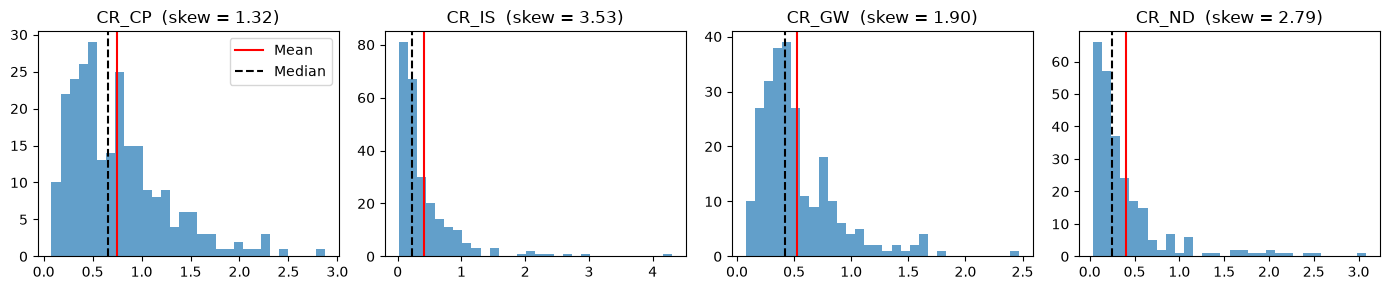

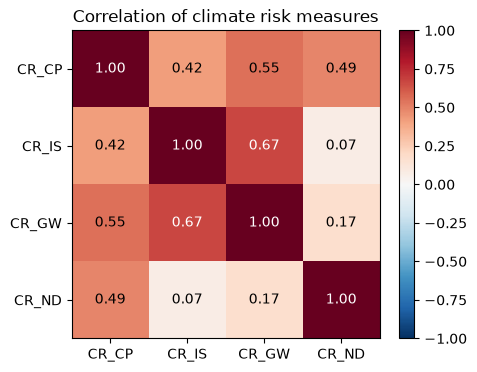

In [5]:
t1 = pd.DataFrame({'Mean': cr.mean(), '1st': cr.quantile(.01), 'Median': cr.median(), '99th': cr.quantile(.99),
                   'Std': cr.std(), 'Skew': cr.skew(), 'rho(1)': cr.apply(lambda s: s.autocorr())})
display(t1.round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))                    # distributions: mean vs median shows the skew
for ax, c in zip(axes, CRS):
    ax.hist(cr[c].dropna(), bins=30, color='tab:blue', alpha=.7)
    ax.axvline(cr[c].mean(), color='red', lw=1.5, label='Mean'); ax.axvline(cr[c].median(), color='k', ls='--', lw=1.5, label='Median')
    ax.set_title(f'{c}  (skew = {cr[c].skew():.2f})')
axes[0].legend(); plt.tight_layout(); plt.show()

C = cr.corr()                                                      # correlation heatmap
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(CRS); ax.set_yticks(range(4)); ax.set_yticklabels(CRS)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{C.iloc[i, j]:.2f}', ha='center', va='center', color='white' if abs(C.iloc[i, j]) > .6 else 'black')
plt.colorbar(im); ax.set_title('Correlation of climate risk measures'); plt.show()

Comments:
- All four measures are strongly positively skewed: most months are calm, with a few months of very intense coverage.
- The measures are positively correlated, supporting the idea of a common underlying climate-risk component.
- CR_CP has extreme values but focuses on US policy, so it is less directly relevant for global agricultural markets.

### 1.2 Aggregate index PC-CR
First principal component of the four standardized proxies, standardized.
- `PC_CR`: estimated on the full sample, as in the paper; used for the in-sample replication.
- `PC_CR_rt`: **real-time** version, standardization and PCA weights re-estimated each month with data up to that month only (no look-ahead); used out of sample and in the trading strategy.

Correlation real-time vs full-sample PC-CR: 0.907


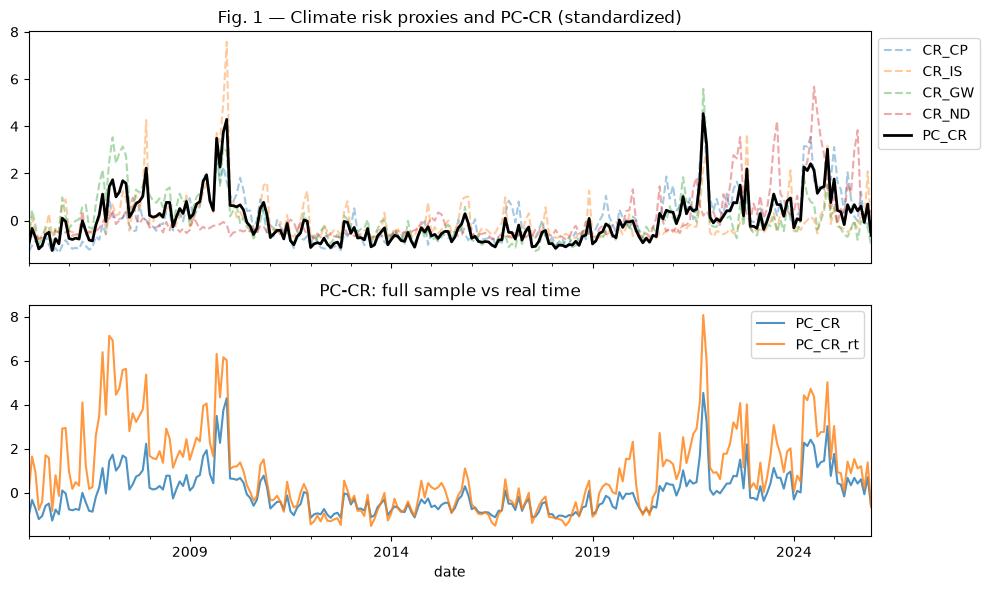

In [6]:
def pc1(X):
    Z = z(X); v = np.linalg.eigh(Z.cov())[1][:, -1]                 # weights = eigenvector of the largest eigenvalue
    return z(Z @ (v * np.sign(v.sum())))

def pc1_realtime(X, min_obs=36):
    out = {}
    for i in range(min_obs - 1, len(X)):
        Xh = X.iloc[:i + 1]; Zh = (Xh - Xh.mean()) / Xh.std()       # standardization with data up to t
        v = np.linalg.eigh(Zh.cov())[1][:, -1]; v *= np.sign(v.sum())   # PCA weights with data up to t
        out[X.index[i]] = Zh.iloc[-1] @ v                            # index value at t
    return pd.Series(out)

df = cr.copy()
df['PC_CR'] = pc1(cr[CRS])
df['PC_CR_rt'] = pc1_realtime(cr_all).loc[START:END]
print('Correlation real-time vs full-sample PC-CR:', round(df.PC_CR.corr(df.PC_CR_rt), 3))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
z(df[CRS]).plot(ax=a1, alpha=.4, ls='--'); df.PC_CR.plot(ax=a1, color='k', lw=2, label='PC_CR')
a1.set_title('Fig. 1 — Climate risk proxies and PC-CR (standardized)'); a1.legend(bbox_to_anchor=(1, 1))
df[['PC_CR', 'PC_CR_rt']].plot(ax=a2, alpha=.8); a2.set_title('PC-CR: full sample vs real time')
plt.tight_layout(); plt.show()

### 2. Economic controls variables and risk-free rate

In [7]:
fred = lambda s: pd.to_numeric(
    read_csv_https(FRED + s, index_col=0, parse_dates=True).iloc[:, 0],
    errors='coerce'
).resample('MS').mean()
px = yf.download(['^GSPC', '^SP500TR'], start='1999-01-01', end='2026-01-01', interval='1mo', auto_adjust=False)['Close']
px.index = px.index.to_period('M').to_timestamp()
rf = fred('DTB4WK') / 1200                                                        # 1-month T-bill, monthly decimal
div = (px['^SP500TR'].pct_change() - px['^GSPC'].pct_change()) * px['^GSPC'].shift(1)   # implied monthly dividends

E = pd.DataFrame({'DP': np.log(div.rolling(12).sum()) - np.log(px['^GSPC']),   # log D12 - log P
                  'EXRET': px['^SP500TR'].pct_change() - rf,                   # S&P 500 excess return
                  'LTY': fred('GS10'), 'TBL': fred('TB3MS'), 'INFL': np.log(fred('CPIAUCSL')).diff(),
                  'EXI': fred('DTWEXBGS'), 'IP': 100 * np.log(fred('INDPRO')).diff(), 'KI': fred('IGREA')}).loc[START:END]
CTRL = list(E.columns)
E = z(E)
E['PC_ECON'] = pc1(E[CTRL].dropna())
rf = rf.loc[START:END]

[*********************100%***********************]  2 of 2 completed


### 3. Google Trends: climate search attention

Google Trends search interest is collected for four climate-related topics matching the news proxies. The data are retrieved from a pre-existing CSV file (gt_cache.csv) hosted on GitHub and aggregated to monthly frequency.

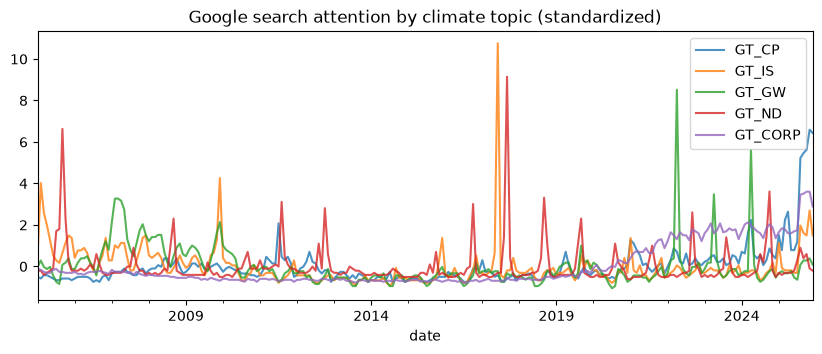

In [8]:
GT_URL = (
    "https://raw.githubusercontent.com/Pierrepalacin/"
    "Machine-Learning-for-Portfolio-Management/main/gt_cache.csv"
)

trends = read_csv_https(
    GT_URL, index_col=0, parse_dates=True
).to_dict("series")

HAS_GT = len(trends) > 0

if HAS_GT:
    GT_all = pd.DataFrame({
        k: pd.to_numeric(
            v.astype(str).str.replace('<1', '0'),
            errors='coerce'
        ).resample('MS').mean()
        for k, v in trends.items()
    }).loc[:END]

    GT4 = [
        c for c in ['GT_CP', 'GT_IS', 'GT_GW', 'GT_ND']
        if c in GT_all
    ]

    GT_all.loc[START:END].apply(z).plot(
        figsize=(10, 3.5),
        alpha=.8,
        title='Google search attention by climate topic (standardized)'
    )
    plt.show()

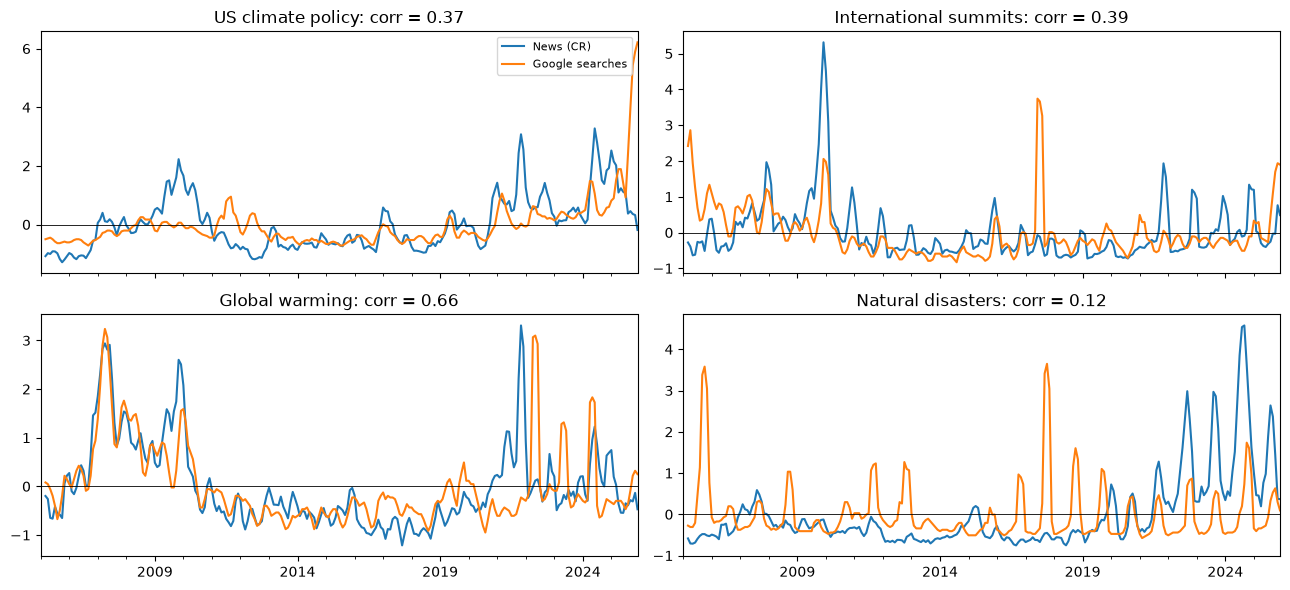

In [9]:
# Does public attention follow climate news? One panel per topic, 3-month averages, standardized
names = {'CP': 'US climate policy', 'IS': 'International summits', 'GW': 'Global warming', 'ND': 'Natural disasters'}
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for ax, (k, name) in zip(axes.flat, names.items()):
    news = z(df[f'CR_{k}'].loc[START:END]).rolling(3).mean()
    att = z(GT_all[f'GT_{k}'].loc[START:END]).rolling(3).mean()
    news.plot(ax=ax, color='tab:blue', lw=1.5, label='News (CR)'); att.plot(ax=ax, color='tab:orange', lw=1.5, label='Google searches')
    ax.set_title(f'{name}: corr = {news.corr(att):.2f}'); ax.axhline(0, color='k', lw=.6); ax.set_xlabel('')
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Comment** 

Public attention follows climate news unevenly across topics. It tracks the news most closely for **global warming** (correlation 0.66): both rise together in 2007–2010, then stay low until the 2020s. For **US climate policy** and **international summits** (0.37–0.39), the two series agree only in part: some news peaks barely show up in searches (e.g. 2009), while some search spikes have no matching news peak. For **natural disasters** (0.12), searches jump with individual events such as major hurricanes, while the news measure trends up after 2020, so the two carry largely different information. Global warming is therefore the topic where news and attention measure the same underlying concern, whichi hints to the idea that *global warming + attention* could be a good predictor.

### 4. Tradable assets

Daily futures and DBA from Yahoo Finance. Daily moves above 10% (contract rolls) are removed, then returns are summed into monthly log returns.

In [10]:
TICK = {'Corn': 'ZC=F', 'Wheat': 'ZW=F', 'Soybeans': 'ZS=F', 'Coffee': 'KC=F', 'Cocoa': 'CC=F',
        'Sugar': 'SB=F', 'Cotton': 'CT=F', 'DBA': 'DBA'}
px_d = yf.download(list(TICK.values()), start='2005-01-01', end='2026-01-01', auto_adjust=True)['Close']
px_d = px_d.rename(columns={v: k for k, v in TICK.items()})[list(TICK)]
rd = 100 * np.log(px_d).diff()
rd = rd.where(rd.abs() < 10)                                           # remove artificial jumps at futures rolls
rd['Futures basket'] = rd[[c for c in TICK if c != 'DBA']].mean(axis=1)   # equal-weight basket of the 7 futures
YM = rd[['Futures basket', 'DBA']].resample('MS').sum(min_count=1).loc[START:END]   # monthly log returns (%)

[*********************100%***********************]  8 of 8 completed


## II- Statistical Analysis

- **Predictive regression:** $R_{t+1:t+h} = \alpha + \beta\,CR_t + \varepsilon_{t+1:t+h}$, where $R_{t+1:t+h}$ is the average monthly return over the next $h$ months.
- **t-statistics:** Newey–West and Hodrick, which correct for overlapping observations (relevant at $h = 6, 12$).
- **Out-of-sample forecasts:** each month, the regression is re-estimated using only past data; the benchmark is the historical average return. Optional **sign restriction**: if the estimated climate slope is negative, the forecast is the historical average. This restriction is used in particular in the trading strategy.
- **Evaluation:** $R^2_{OS} = 1 - \sum (R-\hat R)^2 / \sum (R-\bar R)^2$.

In [11]:
fwd = lambda r, h: r.rolling(h).mean().shift(-h)                 # R_{t+1:t+h} (average monthly return)

def reg(y1, X, h):
    'Regress fwd(y1,h) on const + X_t. Returns slopes, NW-t, HD-t, R2.'
    y1, X = y1.loc[START:END], pd.DataFrame(X).rename(columns=str).loc[START:END]
    d = pd.concat([fwd(y1, h).rename('y'), y1.shift(-1).rename('y1n'), X, X.rolling(h).sum().add_suffix('_s')], axis=1).dropna()
    y, Z = d.y.values, np.column_stack([np.ones(len(d)), d[X.columns]])
    T = len(y); b = np.linalg.lstsq(Z, y, rcond=None)[0]; e = y - Z @ b
    Q = np.linalg.inv(Z.T @ Z / T)
    u = Z * e[:, None]; S = u.T @ u / T                            # Newey-West, lag h
    for l in range(1, h + 1):
        G = u[l:].T @ u[:-l] / T; S += (1 - l / (h + 1)) * (G + G.T)
    nw = b / np.sqrt(np.diag(Q @ S @ Q) / T)
    Zs = np.column_stack([np.full(T, h), d[[c + '_s' for c in X.columns]]])   # Hodrick (1992) 1B
    w = Zs * ((d.y1n - d.y1n.mean()).values / h)[:, None]
    hd = b / np.sqrt(np.diag(Q @ (w.T @ w / T) @ Q) / T)
    return b[1:], nw[1:], hd[1:], 1 - e.var() / y.var()

def oos(y1, X, h, start=OOS_START, sign=False):
    'Recursive forecasts f of R_{t+1:t+h} made at t (data with s+h<=t) and prevailing mean pm. sign=True: CT sign restriction on the 1st predictor.'
    X = pd.DataFrame(X).rename(columns=str)
    d = pd.concat([fwd(y1.loc[START:END], h).rename('y'), X], axis=1).loc[START:END]
    out = []
    for i, t in enumerate(d.index):
        if t < pd.Timestamp(start) - pd.DateOffset(months=1) or np.isnan(d.y.iloc[i]): continue
        tr = d.iloc[:i - h + 1].dropna(); pm = tr.y.mean()
        b = np.linalg.lstsq(np.column_stack([np.ones(len(tr)), tr[X.columns]]), tr.y.values, rcond=None)[0]
        f = pm if (sign and b[1] < 0) else b[0] + d[X.columns].iloc[i].values @ b[1:]
        out.append((t, d.y.iloc[i], f, pm))
    return pd.DataFrame(out, columns=['t', 'y', 'f', 'pm']).set_index('t')

def lrv(a, L):                                                    # Newey-West long-run variance
    a = a - a.mean(); s = a @ a / len(a)
    for l in range(1, L + 1): s += 2 * (1 - l / (L + 1)) * (a[l:] @ a[:-l]) / len(a)
    return s

def evaluate(o, h):
    'R2_OS (%) vs the benchmark column pm and Clark-West statistic.'
    e, eb = o.y - o.f, o.y - o.pm
    adj = (eb**2 - (e**2 - (o.pm - o.f)**2)).values
    cw = adj.mean() / np.sqrt(lrv(adj, h - 1) / len(adj))
    return 100 * (1 - (e**2).sum() / (eb**2).sum()), cw

### 1. In-sample results

In [12]:
# In-sample predictive regressions on tradable assets
PRED = ['PC_CR'] + CRS
t2t = {}
for a in YM.columns:
    for p in PRED:
        for h in H:
            b, nw, hd, r2 = reg(YM[a], z(df[p]), h)
            t2t.setdefault((a, p), {}).update({(h, 'beta'): round(b[0], 2), (h, 'NW-t'): star(nw[0]), (h, 'HD-t'): star(hd[0]), (h, 'R2%'): round(100 * r2, 2)})
pd.DataFrame(t2t).T

1                           6                     \
                      beta    NW-t    HD-t   R2%  beta     NW-t     HD-t   
Futures basket PC_CR  0.47   1.60*   1.61*  0.81  0.43   1.99**   1.67**   
               CR_CP  0.27    0.95    0.91  0.26   0.4   2.08**    1.56*   
               CR_IS  0.43    1.11   1.31*  0.67  0.17     0.73     0.69   
               CR_GW  0.61  2.02**  2.02**  1.34  0.49  2.43***   1.78**   
               CR_ND -0.02   -0.08   -0.08   0.0  0.19     1.25     0.76   
DBA            PC_CR  0.42   1.57*  1.67**  0.91  0.46   2.21**   2.25**   
               CR_CP  0.28    1.13    1.13  0.37  0.49  3.23***  2.48***   
               CR_IS  0.31    0.91    1.05  0.52  0.14     0.67     0.73   
               CR_GW  0.36   1.30*   1.34*  0.68  0.39   1.82**    1.56*   
               CR_ND  0.33   1.53*   1.39*  0.59  0.46  3.65***  2.37***   

                              12                           
                       R2%  beta     NW-t     HD-t    R2%  
Futures basket PC_CR  3.92   0.5  3.03***   1.91**  10.61  
               CR_CP  3.34  0.46   2.14**   1.87**   8.42  
               CR_IS  0.59  0.29   2.14**     1.20   3.66  
               CR_GW  5.14  0.55  3.24***   1.82**  13.34  
               CR_ND  0.72  0.12     0.92     0.65    0.6  
DBA            PC_CR  5.43  0.46  3.26***   2.21**  10.77  
               CR_CP  5.63  0.49  3.91***  2.61***  10.48  
               CR_IS  0.51  0.17    1.58*     0.90   1.42  
               CR_GW  3.93  0.42   2.10**    1.47*   9.05  
               CR_ND  5.08  0.41  3.55***  2.56***   7.92

**Comments**

Climate news help predicts tradable agricultural returns, with positive coefficients that grow in significance with the horizon (R² of about 10–13% at 12 months for PC-CR and global warming). The proxies do not behave the same way on both assets. On the futures basket, global warming is the strongest predictor at every horizon and dominates PC-CR (R² of 13.3% vs 10.6% at 12 months): averaging it with weaker proxies (international summits, natural disasters) dilutes the signal. On DBA, PC-CR is slightly stronger, and natural disasters and US climate policy are the best single proxies, which may reflect DBA's different composition (e.g. livestock). Global warming is the only proxy that is significant on both assets at all horizons; together with its out-of-sample performance, this supports using it rather than the aggregate index as the main signal.

### 2. Controlling for economic drivers

Does climate risk still predict returns once we control for the usual economic drivers?
$R_{t+1:t+h} = \alpha + \beta\,\text{CR-GW}_t + \psi E_t + \varepsilon_{t+1:t+h}$, adding one control $E_t$ at a time: stock valuation (DP) and returns (EXRET), long- and short-term rates (LTY, TBL), inflation (INFL), the US dollar (EXI), industrial production (IP), global activity (KI), and PC-ECON, the first principal component of all eight.
- **β:** effect of climate risk after the control. **ΔR²:** extra explanatory power from adding PC-CR to the control alone.

In [13]:
# Global warming risk controlling for each economic variable, tradable assets
t3 = {}
for a in YM.columns:
    for e in E.columns:
        X = pd.concat([z(df.CR_GW).rename('CR_GW'), E[e]], axis=1).dropna()
        for h in H:
            b, nw, hd, r2 = reg(YM[a], X, h)
            r2e = reg(YM[a], X[[e]], h)[3]
            t3.setdefault((a, e), {}).update({(h, 'beta'): round(b[0], 2), (h, 'NW-t'): star(nw[0]), (h, 'HD-t'): star(hd[0]), (h, 'dR2%'): round(100 * (r2 - r2e), 2)})
pd.DataFrame(t3).T

1                           6                    \
                        beta    NW-t    HD-t  dR2%  beta     NW-t    HD-t   
Futures basket DP       0.59  1.93**  1.93**  1.26  0.48  2.37***  1.70**   
               EXRET    0.61  2.02**  2.02**  1.33  0.49  2.42***  1.78**   
               LTY      0.67  2.18**  2.25**  1.46  0.52  2.49***  1.96**   
               TBL      0.61  2.02**  2.00**  1.27  0.46  2.39***  1.71**   
               INFL     0.65  2.18**  2.13**  1.51  0.52  2.60***  1.89**   
               EXI      0.63  2.09**  2.09**  1.44  0.55  2.79***  2.01**   
               IP       0.56  1.82**  1.85**  1.14  0.48  2.35***  1.74**   
               KI       0.25    0.67    0.66  0.15  0.31     1.00    1.04   
               PC_ECON  0.54  1.73**  1.68**  0.94  0.47  2.41***  1.70**   
DBA            DP       0.32    1.12    1.14  0.52  0.35   1.74**   1.35*   
               EXRET    0.36   1.31*   1.34*  0.68  0.39   1.82**   1.56*   
               LTY      0.32    1.21    1.23  0.47  0.35   1.73**   1.61*   
               TBL      0.27    1.00    1.00  0.36  0.29    1.54*    1.21   
               INFL     0.33    1.16    1.16  0.53  0.43   2.05**  1.69**   
               EXI      0.42   1.53*   1.57*  0.87  0.46  2.38***  1.94**   
               IP       0.32    1.14    1.17  0.54  0.38   1.75**   1.50*   
               KI      -0.01   -0.02   -0.02   0.0  0.36     1.23   1.38*   
               PC_ECON  0.12    0.43    0.42  0.07  0.22     1.27    0.92   

                                12                           
                        dR2%  beta     NW-t     HD-t   dR2%  
Futures basket DP       4.89  0.55  3.18***   1.76**   13.0  
               EXRET    5.13  0.55  3.25***   1.83**  13.34  
               LTY      4.94  0.57  3.22***   2.13**  12.19  
               TBL      4.28  0.52  3.29***   1.77**  10.96  
               INFL     5.66  0.61  4.01***   2.02**  15.94  
               EXI      6.25  0.59  3.29***   1.97**  15.06  
               IP       4.96  0.55  3.24***   1.81**  13.29  
               KI       1.31  0.57  2.70***  2.37***   8.69  
               PC_ECON  4.04  0.56  3.57***   1.88**  11.54  
DBA            DP        3.1  0.38   1.93**    1.30*   7.34  
               EXRET    3.93  0.42   2.10**    1.48*   9.06  
               LTY       2.6   0.4   2.05**   1.76**    6.9  
               TBL      1.98  0.32   1.94**     1.23   4.94  
               INFL     4.51  0.46  2.33***    1.59*  10.07  
               EXI      5.31   0.5  2.45***   1.84**  12.21  
               IP       3.71  0.42   2.07**    1.45*   8.87  
               KI       1.98  0.57  2.55***  2.75***   9.86  
               PC_ECON  1.09  0.29   1.71**     1.13   3.58

**Comments.** 

On the futures basket, global warming risk keeps predicting returns after controlling for each economic variable: its coefficient stays close to the unconditional estimate (β ≈ 0.5–0.65) and is significant at every horizon, adding 11–16% of R² at 12 months. The exception is global real activity (KI, Kilian's index): it absorbs the climate effect at 1–6 months, but not at 12 months (β = 0.57, significant at 1%). 

On DBA, the evidence is weaker: the climate effect is not significant at 1 month and survives most controls at 6–12 months, but global activity and PC-ECON absorb a large part of it. Part of the short-horizon climate signal therefore overlaps with the global demand cycle, while the 12-month effect is largely independent of economic conditions. This supports the 6-month horizon of the strategy and the comparison with the macro signal later.

Extension: control for the first 1–3 principal components of the eight economic variables jointly.

In [14]:
Zc8 = E[CTRL].dropna()
val, vec = np.linalg.eigh(Zc8.cov()); order = val.argsort()[::-1]; val, vec = val[order], vec[:, order]
F = pd.DataFrame(Zc8.values @ vec[:, :3], index=Zc8.index, columns=['F1', 'F2', 'F3'])
print('Variance of the controls explained by each component (%):', (100 * val / val.sum()).round(1))

# Global warming risk controlling for the first k principal components of the controls, tradable assets
tf = {}
for a in YM.columns:
    for k in [1, 2, 3]:
        X = pd.concat([z(df.CR_GW).rename('CR_GW'), F.iloc[:, :k]], axis=1).dropna()
        for h in H:
            b, nw, hd, r2 = reg(YM[a], X, h)
            r2f = reg(YM[a], X.iloc[:, 1:], h)[3]
            tf[(a, f'{k} comp.', h)] = {'beta GW': round(b[0], 2), 'NW-t': star(nw[0]), 'HD-t': star(hd[0]), 'ΔR2 %': round(100 * (r2 - r2f), 2)}
pd.DataFrame(tf).T

Variance of the controls explained by each component (%): [30.7 20.7 16.9 12.8  9.4  4.8  3.5  1.2]


beta GW     NW-t     HD-t  ΔR2 %
Futures basket 1 comp. 1     0.54   1.72**   1.68**   0.94
                       6     0.47  2.39***   1.69**   4.02
                       12    0.56  3.54***   1.86**  11.43
               2 comp. 1     0.58   1.69**   1.68**    0.9
                       6     0.54   2.05**   1.96**   4.33
                       12     0.7  3.10***  2.77***  14.35
               3 comp. 1     0.53    1.44*    1.53*   0.75
                       6     0.54   2.04**   1.93**   4.35
                       12    0.71  3.60***  2.81***  14.91
DBA            1 comp. 1     0.12     0.43     0.42   0.07
                       6     0.22     1.25     0.92   1.09
                       12    0.29   1.70**     1.11   3.54
               2 comp. 1     0.17     0.57     0.54    0.1
                       6     0.37   1.75**   1.70**   2.41
                       12     0.5  2.39***  2.57***   8.57
               3 comp. 1     0.13     0.41     0.40   0.06
                       6     0.38   1.82**   1.71**   2.53
                       12    0.51  2.81***  2.63***   9.06

**Comment** 

Summarizing the eight controls with their first one to three principal components confirms the previous table. On the futures basket, global warming risk remains significant at every horizon whatever the number of components, and its coefficient even rises at 12 months (β ≈ 0.7, adding about 14–15% of R²). On DBA, the first component alone absorbs most of the climate effect, but with two or three components it is again significant at 6 and 12 months (β ≈ 0.4–0.5, significant at 1–5%), though never at 1 month. Overall, the climate signal is largely independent of economic conditions on the futures basket, and at horizons of six months or more on DBA.

The predictive information in climate news is to a certain extent independent of general economic and financial conditions.
Together with the previous tables, this suggests that the climate signal is more reliable on the futures basket than on DBA, where its predictive power is weaker and partly shared with the economic cycle.

### 3. Out-of-sample Results

Recursive forecasts from `OOS_START`; benchmark = historical average. `PC_CR_rt` is the look-ahead-free version of PC-CR.

In [15]:
# Out-of-sample forecasts on tradable assets (vs historical mean)
PRED_OOS = [ 'PC_CR_rt'] + CRS
O = {(a, p, h): oos(YM[a], df[p], h) for a in YM.columns for p in PRED_OOS for h in H}
t4 = {}
for (a, p, h), o in O.items():
    r2, cw = evaluate(o.dropna(), h)
    t4.setdefault((a, p), {}).update({(h, 'R2OS%'): round(r2, 2), (h, 'CW'): cw_star(cw)})
pd.DataFrame(t4).T

1              6               12         
                        R2OS%      CW  R2OS%       CW  R2OS%       CW
Futures basket PC_CR_rt  0.47   1.37*  11.41   2.25**   9.99   2.30**
               CR_CP    -0.44    0.69   0.62    1.39*  -11.1    1.51*
               CR_IS    -0.13    0.70   0.47     0.56   0.74     0.68
               CR_GW     1.28  1.88**  12.74  2.73***  13.43  2.78***
               CR_ND    -3.03   -0.66 -22.66     0.42  -31.7     0.80
DBA            PC_CR_rt  1.33  1.74**  11.46  2.43***  10.88  3.17***
               CR_CP    -0.07    0.67  11.19   2.32**  10.64  2.83***
               CR_IS    -0.05    0.53   0.03     0.26  -0.68     0.26
               CR_GW     1.05  1.84**   8.55  2.43***   7.06  2.49***
               CR_ND    -1.39    0.40 -11.42    1.54*   0.31  2.77***

**Comment - out of sample** 

Two signals beat the historical mean on both assets at every horizon, with significant Clark–West statistics: global warming risk and the real-time PC-CR. On the futures basket, global warming is clearly the best (R²OS = 1.3%, 12.7% and 13.4% at 1, 6 and 12 months), ahead of the real-time PC-CR (0.5%, 11.4%, 10.0%). On DBA, the ranking is reversed: the real-time PC-CR do best (about 1.5%, 12% and 11–13%), followed by US climate policy at 6–12 months, while global warming remains positive and significant but smaller (1.1%, 8.6%, 7.1%). Natural-disaster risk fails out of sample on both assets, and international summits add nothing. 

Overall, the out-of-sample evidence confirms the in-sample tables: global warming is the best signal for the futures basket, while DBA benefits more from the broader climate index.

### 4. Asset allocation

**Question.** Statistically significant forecasts are not necessarily valuable. Would a mean–variance investor gain from using climate-risk forecasts?

**Strategy.** Each month, the investor splits her wealth between a tradable asset (futures basket or DBA) and T-bills, investing the share $w_t = \hat R^e_{t+1} / (\gamma\,\hat\sigma^2_{t+1})$, capped to [0%, 150%]. The forecast $\hat R^e$ comes from global warming or the real-time PC-CR, the variance $\hat\sigma^2$ from the past 5 years, and risk aversion is γ = 3. The benchmarks are the same rule using the historical mean, and buy-and-hold.

- **CER gain:** yearly fee the investor would pay to use the climate forecasts instead of the historical mean.
- **SR:** annualized Sharpe ratio.
- **0 / 30 bps:** trading cost per unit of change in the weight.

In [16]:
def mv_weights(f, ex, rf_, gamma, lo, hi):
    'f: forecast (%) made at t -> weight held over t+1.'
    sig2 = ex.rolling(60, min_periods=48).var().shift(1)
    return ((f.reindex(ex.index).shift(1) / 100 - rf_) / (gamma * sig2)).clip(lo, hi)

def mv_perf(w, ex, rf_, gamma, cost):
    rp = w * ex + rf_ - cost * w.diff().abs().fillna(0)
    return rp.mean() - gamma / 2 * rp.var(), np.sqrt(12) * (rp - rf_).mean() / (rp - rf_).std()

def allocation(o, r_simple, rf_, name='Climate', lo=-0.5, hi=1.5):
    ex = (r_simple - rf_).dropna(); rf_ = rf_.reindex(ex.index); res = {}
    for gamma in [3]:                                              # risk aversion, as in the paper
        w_m, w_pm = mv_weights(o.f, ex, rf_, gamma, lo, hi), mv_weights(o.pm, ex, rf_, gamma, lo, hi)
        idx = w_m.dropna().index.intersection(w_pm.dropna().index)
        idx = idx[idx >= o.index[0] + pd.DateOffset(months=1)]
        W = {'Prevailing mean': w_pm[idx], name: w_m[idx], 'Buy and hold': pd.Series(1.0, idx)}
        for c in [0, 30]:                                          # trading cost (bps)
            cer_pm = mv_perf(W['Prevailing mean'], ex[idx], rf_[idx], gamma, c / 1e4)[0]
            for k, w in W.items():
                cer, sr = mv_perf(w, ex[idx], rf_[idx], gamma, c / 1e4)
                res.setdefault((gamma, k), {}).update({(f'{c}bps', 'CER gain%'): '-' if k == 'Prevailing mean' else round(1200 * (cer - cer_pm), 2),
                                                       (f'{c}bps', 'SR'): round(sr, 2)})
    return pd.DataFrame(res).T

for a in YM.columns:                                               # tradable assets, 1-month forecasts, two climate signals
    r_s = np.exp(YM[a] / 100) - 1
    t5 = pd.concat([allocation(O[a, p, 1], r_s, rf, name=lab, lo=0) for p, lab in [('CR_GW', 'Global warming'), ('PC_CR_rt', 'PC-CR (real time)')]])
    print(a); display(t5[~t5.index.duplicated()])                 # benchmark rows shown once

Futures basket


0bps           30bps      
                    CER gain%    SR CER gain%    SR
3 Prevailing mean           -  0.19         -  0.18
  Global warming         1.75  0.39      1.12   0.3
  Buy and hold          -1.64  0.14     -1.49  0.14
  PC-CR (real time)      1.08  0.31       0.5  0.25

DBA


0bps           30bps      
                    CER gain%    SR CER gain%    SR
3 Prevailing mean           - -0.39         - -0.42
  Global warming         1.26  0.68      1.06  0.55
  Buy and hold          -2.09 -0.03     -2.07 -0.03
  PC-CR (real time)      0.36  0.07     -0.02 -0.06

**Comment** 

On tradable assets, the climate forecasts have economic value for a mean–variance investor (γ = 3). On the futures basket, using global warming forecasts instead of the historical mean is worth 1.8% per year before costs and 1.1% after 30 bps costs (certainty-equivalent gain), with a Sharpe ratio of 0.39 (0.30 after costs) against 0.19 for the historical-mean strategy and 0.14 for buy-and-hold. 

On DBA, the gain is 1.3% before costs and 1.1% after, with Sharpe ratios of 0.68 and 0.55, while the historical-mean strategy and buy-and-hold have negative Sharpe ratios, because DBA performed poorly over the period. Here, the real-time PC-CR has a Sharpe ratio close to zero after costs: despite its better out-of-sample R²OS on DBA, the broader index brings less economic value than global warming in this allocation.

## III- Investor attention (Google Trends)

Does climate risk predict returns better when the public pays attention? Nested models, with abnormal attention $A$ (searches vs their past-12-month average, Da et al., 2011) on the matching topic:
- **M1:** $R = a + b_1 C$ (climate risk only) · **M2:** $+\,b_2 A$ · **M3:** $+\,b_3\,C \times A$ (does the climate effect depend on attention?)
- $b_3 > 0$: climate news matters more when attention is high; $b_3 < 0$: more when attention is low (limited attention).
- Key test: **M3 vs M1** out of sample (does attention improve on climate risk alone?).

In [17]:
trends = read_csv_https(
    GT_URL, index_col=0, parse_dates=True
).to_dict("series")   # load saved Google Trends data, no download
HAS_GT = len(trends) > 0                                                     # later sections adapt if Google Trends is missing
if HAS_GT:
    GT_all = pd.DataFrame({k: pd.to_numeric(v.astype(str).str.replace('<1', '0'), errors='coerce').resample('MS').mean()
                           for k, v in trends.items()}).loc[:END]          # monthly, 0-100 scale, from 2004
    GT4 = [c for c in ['GT_CP', 'GT_IS', 'GT_GW', 'GT_ND'] if c in GT_all]

In [18]:
abn = lambda s: s - s.rolling(12).mean().shift(1)                  # abnormal attention: vs past 12 months
if HAS_GT:
    X3 = pd.concat([z(df['CR_GW'].loc[START:END]).rename('C'), z(abn(GT_all['GT_GW']).loc[START:END]).rename('A')], axis=1).dropna()
    X3['CxA'] = X3.C * X3.A                                        # GW news, GW searches, interaction
    models = {'M1': X3[['C']], 'M2': X3[['C', 'A']], 'M3': X3}
    ins, out = {}, {}
    for a in YM.columns:                                           # tradable assets
        y = YM[a]
        for h in H:
            b, nw, hd, r2 = reg(y, X3, h)
            ins[(a, h)] = {'b1 climate': f'{b[0]:.2f} ({star(nw[0])})', 'b2 attention': f'{b[1]:.2f} ({star(nw[1])})',
                           'b3 climate x attention': f'{b[2]:.2f} ({star(nw[2])})', 'b3 HD-t': star(hd[2]),
                           'R2 M1 %': round(100 * reg(y, X3[['C']], h)[3], 2), 'R2 M3 %': round(100 * r2, 2)}
            Om = {m: oos(y, X, h) for m, X in models.items()}
            idx = Om['M1'].index.intersection(Om['M3'].index); row = {}
            for m in models:
                r2os, cw, *_ = evaluate(Om[m].loc[idx], h); row[f'{m} R2OS%'] = round(r2os, 2); row[f'{m} CW'] = cw_star(cw)
            r2os, cw, *_ = evaluate(Om['M3'].loc[idx].assign(pm=Om['M1'].loc[idx, 'f']), h)
            row['M3 vs M1: R2OS%'] = round(r2os, 2); row['M3 vs M1: CW'] = cw_star(cw)
            out[(a, h)] = row
    print('In-sample (global warming news and searches): coefficient (NW-t) and R2'); display(pd.DataFrame(ins).T)
    print(f'Out-of-sample (from {OOS_START[:4]}): each model vs historical mean, and M3 vs climate-only M1'); display(pd.DataFrame(out).T)
else:
    print('Google Trends data not available yet: run section 1.5 once the data is downloaded.')

In-sample (global warming news and searches): coefficient (NW-t) and R2


b1 climate     b2 attention b3 climate x attention  \
Futures basket 1    0.69 (2.05**)    -0.21 (-0.67)          -0.05 (-0.16)   
               6    0.52 (2.11**)  -0.55 (-2.04**)            0.18 (1.13)   
               12  0.46 (2.50***)  -0.21 (-1.78**)         0.25 (2.67***)   
DBA            1     0.46 (1.42*)    -0.03 (-0.11)          -0.16 (-0.60)   
               6     0.40 (1.42*)  -0.41 (-1.87**)            0.15 (1.04)   
               12    0.28 (1.41*)  -0.22 (-1.69**)         0.32 (3.07***)   

                  b3 HD-t R2 M1 % R2 M3 %  
Futures basket 1    -0.16    1.34    1.55  
               6     0.96    5.14    9.56  
               12   1.61*   13.34   16.54  
DBA            1    -0.58    0.68    0.93  
               6     0.92    3.93    6.92  
               12  2.25**    9.05   15.44

Out-of-sample (from 2013): each model vs historical mean, and M3 vs climate-only M1


M1 R2OS%    M1 CW M2 R2OS%    M2 CW M3 R2OS%    M3 CW  \
Futures basket 1      1.28   1.88**     -0.0   1.77**    -1.54     1.14   
               6     12.74  2.73***    13.34  3.16***    -5.92  2.79***   
               12    13.43  2.78***     7.29  2.41***     8.62  3.39***   
DBA            1      1.05   1.84**     0.81    1.57*    -2.16     1.19   
               6      8.55  2.43***    11.45  3.46***    -1.58  3.21***   
               12     7.06  2.49***   -10.25     0.52    -3.35  2.97***   

                  M3 vs M1: R2OS% M3 vs M1: CW  
Futures basket 1            -2.86        -1.24  
               6           -21.39       1.82**  
               12           -5.57         0.93  
DBA            1            -3.24         0.10  
               6           -11.08       2.01**  
               12           -11.2         1.10

**Comment** 

In-sample, attention matters on both assets: abnormal search activity predicts *lower* future returns at 6–12 months, consistent with attention-driven price pressure that later reverses, and the effect of climate news is stronger when attention is high at the 12-month horizon (positive and significant interaction). Adding attention raises the explanatory power, mostly at long horizons.

Out of sample, the picture is more selective. Adding attention to global warming news (M2) improves on climate news alone at the 6-month horizon, on both assets, which is the horizon used by the strategy, but not at 1 or 12 months. Combined with the broad PC-CR index and all-topic searches, attention does not help. The interaction model (M3) performs poorly against the historical mean everywhere: its Clark–West statistics against the climate-only model are sometimes significant, so the interaction contains some information, but the extra parameter adds more estimation noise than predictive gain. Attention is therefore useful only in its simplest form, combined with global warming news at medium horizons.

## IV- Trading strategy (monthly)

**Idea.** Instead of the all-or-nothing weights of section II.4, the investor stays invested in a tradable agricultural asset (futures basket or DBA) and only **tilts** her exposure up or down according to the climate signal. This keeps turnover and trading costs low.

**Rule, each month:**
1. **Forecast.** Predict the average monthly return over the next `H_S` = 6 months with a climate predictor, using only past data. If the estimated climate slope is negative, the forecast is the historical average, so there is no climate bet.
2. **Signal.** Compare the forecast with the historical average and standardize the gap by its past variability ($z_t$): positive when the climate outlook is better than usual.
3. **Exposure.** Hold $1 + 0.5\,z_t$ of the asset, capped to **[50%, 150%]**, and the rest in T-bills. Trading costs are 30 bps per unit of turnover.

**Choosing the predictor.** The candidates are global warming and the real-time PC-CR (to give a second best indicator), with and without attention. They are compared on forecast accuracy over a **validation window** (2013–2018); the best one is then judged on the **test window** (2019–2025), which played no role in the choice. Set `SELECTION` to a candidate's name to force it instead of `'auto'`.

*Note on the horizon.* A 1-month or a 6-month forecast gives almost the same signal, since both are linear in the same climate variable. The 6-month horizon is used because the climate effect is estimated more precisely there. 

In [19]:
SELECTION = 'auto'                    # 'auto' or a candidate name, e.g. 'CR_GW', 'PC-CR (real time)', 'CR_GW x attention'
VALID_END = '2018-06-01'              # Predictor selected over OOS_START–VALID_END; strategy evaluated from TEST_START onward.
TEST_START = '2019-01-01'              
H_S, K_TILT = 6, 0.5                  # forecast horizon (months), tilt strength (exposure = 1 + K_TILT * z)

CAND = {'PC-CR (real time)': df[['PC_CR_rt']], 'CR_GW': df[['CR_GW']]}

if HAS_GT:                            # attention-based candidates (abnormal attention on the matching topic)
   for name, C, A in [('CR_GW', df.CR_GW, abn(GT_all['GT_GW'])),
                      ('PC-CR (real time)', df.PC_CR_rt, abn(GT_all[GT4].apply(z).mean(axis=1)))]:
       X = pd.concat([z(C).rename('C'), z(A.loc[START:END]).rename('A')], axis=1)
       CAND[f'{name} + attention'] = X
       CAND[f'{name} x attention'] = X.assign(CxA=X.C * X.A)

FC = {(a, c): oos(YM[a], X, H_S, sign=True) for a in YM.columns for c, X in CAND.items()}
fq = {}
for (a, c), o in FC.items():
    for lab, sl in [('validation', slice(OOS_START, VALID_END)),('test', slice(TEST_START, END))]:
        r2, cw, *_ = evaluate(o.loc[sl].dropna(), H_S)
        fq.setdefault((a, c), {}).update({(lab, 'R2OS%'): round(r2, 2), (lab, 'CW'): cw_star(cw)})
FQ = pd.DataFrame(fq).T
SEL = {a: (FQ.loc[a][('validation', 'R2OS%')].astype(float).idxmax() if SELECTION == 'auto' else SELECTION) for a in YM.columns}
print('Forecast accuracy of each candidate (vs historical mean)'); display(FQ)
print('Selected predictor:', SEL)

Forecast accuracy of each candidate (vs historical mean)


validation            test  \
                                                  R2OS%       CW  R2OS%   
Futures basket PC-CR (real time)                  25.03  3.37***   0.31   
               CR_GW                              18.86  3.65***   7.69   
               CR_GW + attention                   27.0  3.29***   2.44   
               CR_GW x attention                  24.93  2.69*** -29.92   
               PC-CR (real time) + attention     -17.65  2.47***   5.62   
               PC-CR (real time) x attention     -26.49  2.46***   1.13   
DBA            PC-CR (real time)                  10.97    1.60*  11.34   
               CR_GW                              11.75  2.35***   7.04   
               CR_GW + attention                  12.37   2.13**  10.98   
               CR_GW x attention                   5.84   1.65**  -5.78   
               PC-CR (real time) + attention     -34.67    1.31*   15.8   
               PC-CR (real time) x attention     -66.34     1.27  15.19   

                                                       
                                                   CW  
Futures basket PC-CR (real time)                 0.73  
               CR_GW                            1.29*  
               CR_GW + attention               2.17**  
               CR_GW x attention               1.98**  
               PC-CR (real time) + attention    1.48*  
               PC-CR (real time) x attention    1.38*  
DBA            PC-CR (real time)               1.82**  
               CR_GW                            1.54*  
               CR_GW + attention              2.98***  
               CR_GW x attention              2.84***  
               PC-CR (real time) + attention  2.43***  
               PC-CR (real time) x attention  2.35***

Selected predictor: {'Futures basket': 'CR_GW + attention', 'DBA': 'CR_GW + attention'}


### 1. PnL and Exposure Evolution

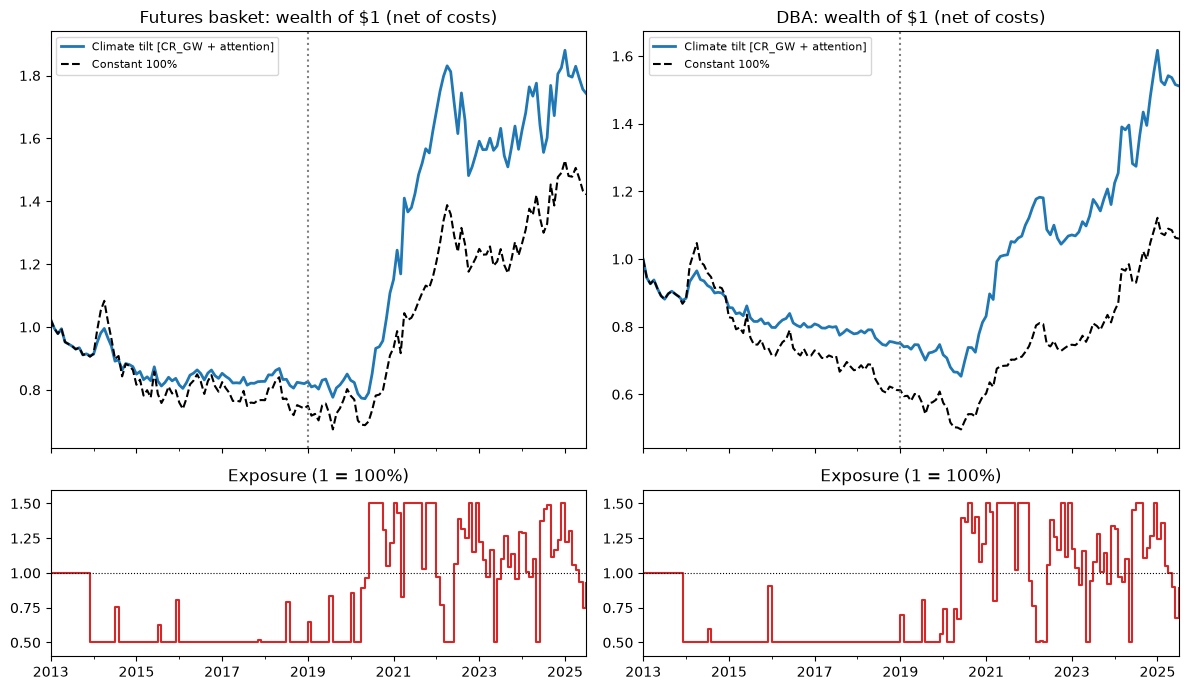

Ann. ret %  \
Futures basket Full (OOS)             Climate tilt [CR_GW + attention]        5.24   
                                      Constant 100%                           3.80   
               Test (after selection) Climate tilt [CR_GW + attention]       12.79   
                                      Constant 100%                          11.00   
DBA            Full (OOS)             Climate tilt [CR_GW + attention]        3.80   
                                      Constant 100%                           1.13   
               Test (after selection) Climate tilt [CR_GW + attention]       11.44   
                                      Constant 100%                           9.05   

                                                                        Ann. vol %  \
Futures basket Full (OOS)             Climate tilt [CR_GW + attention]       13.05   
                                      Constant 100%                          14.24   
               Test (after selection) Climate tilt [CR_GW + attention]       16.35   
                                      Constant 100%                          14.67   
DBA            Full (OOS)             Climate tilt [CR_GW + attention]       10.23   
                                      Constant 100%                          11.58   
               Test (after selection) Climate tilt [CR_GW + attention]       12.59   
                                      Constant 100%                          11.84   

                                                                          SR  \
Futures basket Full (OOS)             Climate tilt [CR_GW + attention]  0.28   
                                      Constant 100%                     0.16   
               Test (after selection) Climate tilt [CR_GW + attention]  0.62   
                                      Constant 100%                     0.57   
DBA            Full (OOS)             Climate tilt [CR_GW + attention]  0.22   
                                      Constant 100%                    -0.04   
               Test (after selection) Climate tilt [CR_GW + attention]  0.71   
                                      Constant 100%                     0.55   

                                                                        Max DD %  \
Futures basket Full (OOS)             Climate tilt [CR_GW + attention]    -24.59   
                                      Constant 100%                       -37.76   
               Test (after selection) Climate tilt [CR_GW + attention]    -19.07   
                                      Constant 100%                       -15.59   
DBA            Full (OOS)             Climate tilt [CR_GW + attention]    -34.57   
                                      Constant 100%                       -52.62   
               Test (after selection) Climate tilt [CR_GW + attention]    -12.97   
                                      Constant 100%                       -18.90   

                                                                        Turnover/yr  
Futures basket Full (OOS)             Climate tilt [CR_GW + attention]         1.46  
                                      Constant 100%                            0.00  
               Test (after selection) Climate tilt [CR_GW + attention]         2.39  
                                      Constant 100%                            0.00  
DBA            Full (OOS)             Climate tilt [CR_GW + attention]         1.47  
                                      Constant 100%                            0.00  
               Test (after selection) Climate tilt [CR_GW + attention]         2.57  
                                      Constant 100%                            0.00

All candidates, test-window Sharpe ratio (reference only — the selected one was chosen on the validation window):


SR (test)
Futures basket PC-CR (real time)                   0.55
               CR_GW                               0.59
               CR_GW + attention                   0.62
               CR_GW x attention                   0.56
               PC-CR (real time) + attention       0.47
               PC-CR (real time) x attention       0.48
DBA            PC-CR (real time)                   0.54
               CR_GW                               0.66
               CR_GW + attention                   0.71
               CR_GW x attention                   0.62
               PC-CR (real time) + attention       0.47
               PC-CR (real time) x attention       0.47

In [20]:
def exposure(o, k=K_TILT):
    'Standardized forecast-minus-mean signal -> exposure in [0.5, 1.5], set at t and held over t+1.'
    sig = ((o.f - o.pm) / (o.f - o.pm).expanding(12).std()).fillna(0)
    e = (1 + k * sig).clip(0.5, 1.5); e.index = e.index + pd.DateOffset(months=1)
    return e

def perf_m(w, r, rf_, cost=COST):
    ret = w * r + (1 - w) * rf_ - cost * w.diff().abs().fillna(0); ex = ret - rf_; W = (1 + ret).cumprod()
    return W, {'Ann. ret %': 1200 * ret.mean(), 'Ann. vol %': 100 * np.sqrt(12) * ret.std(), 'SR': np.sqrt(12) * ex.mean() / ex.std(),
               'Max DD %': 100 * (W / W.cummax() - 1).min(), 'Turnover/yr': 12 * w.diff().abs().mean()}

def backtest(a, c, period):
    e = exposure(FC[(a, c)]); r = (np.exp(YM[a] / 100) - 1).reindex(e.index); rf_ = rf.reindex(e.index)
    ok = r.notna() & rf_.notna(); e, r, rf_ = e[ok].loc[period], r[ok].loc[period], rf_[ok].loc[period]
    return e, perf_m(e, r, rf_), perf_m(pd.Series(1.0, e.index), r, rf_)

PERIODS = {'Full (OOS)': slice(OOS_START, END), 'Test (after selection)': slice(TEST_START, END)}
tab, allc = {}, {}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})
for j, a in enumerate(YM.columns):
    for pl, sl in PERIODS.items():
        e, (Wt, st), (Wc, sc) = backtest(a, SEL[a], sl)
        tab[(a, pl, f'Climate tilt [{SEL[a]}]')] = st; tab[(a, pl, 'Constant 100%')] = sc
        if pl == 'Full (OOS)':
            Wt.plot(ax=axes[0, j], lw=2, label=f'Climate tilt [{SEL[a]}]'); Wc.plot(ax=axes[0, j], ls='--', color='k', label='Constant 100%')
            axes[0, j].axvline(pd.Timestamp(TEST_START), color='grey', ls=':'); axes[0, j].set_title(f'{a}: wealth of $1 (net of costs)')
            axes[0, j].legend(fontsize=8)
            e.plot(ax=axes[1, j], drawstyle='steps-post', color='tab:red'); axes[1, j].axhline(1, color='k', ls=':', lw=.8)   # pandas plot: same date units as the panel above
            axes[1, j].set_ylim(0.4, 1.6); axes[1, j].set_title('Exposure (1 = 100%)'); axes[1, j].set_xlabel('')
    for c in CAND:                                                   # all candidates, for reference only
        allc[(a, c)] = {'SR (test)': backtest(a, c, PERIODS['Test (after selection)'])[1][1]['SR']}
plt.tight_layout(); plt.show()
display(pd.DataFrame(tab).T.round(2))
print('All candidates, test-window Sharpe ratio (reference only — the selected one was chosen on the validation window):')
display(pd.DataFrame(allc).T.round(2))

**Results.** 

The selection on the validation window picks **global warming news + attention** for both assets.

- **Full out-of-sample period (2013–2025).** The climate tilt beats constant exposure on both assets, with higher returns, lower volatility and much smaller drawdowns. On the futures basket, the Sharpe ratio rises from 0.16 to 0.28 and the maximum drawdown shrinks from −38% to −25%. On DBA, the Sharpe ratio goes from −0.04 to 0.22 and the drawdown from −53% to −35%. Turnover stays low (about 1.5 per year).
- **Test window (2019–2025, not used for selection).** The tilt still outperforms: +1.8% per year on the futures basket (Sharpe ratio 0.62 vs 0.57, but with higher volatility and a deeper drawdown) and +2.4% per year on DBA (0.71 vs 0.55, with a smaller drawdown). Among all candidates, the selected predictor also has the highest test-window Sharpe ratio on both assets, and global-warming-based signals beat PC-CR-based ones.
- **Where the gains come from.** The exposure panels show that the strategy made mainly two broad bets. It stayed at the 50% floor from 2014 to mid-2020, a quiet period for climate news, which limited losses during the long commodity decline. It then moved to 150% from mid-2020, as climate news rose, capturing much of the 2020–2022 rally. Since 2022, the exposure has moved more often, with smaller gains.

**Caveat.** The outperformance rests on a few long-lasting positions rather than many independent bets, so it should be read as evidence of a slow-moving climate signal, not of a precise monthly timing tool. The placebo test below checks whether such results could arise by chance.

### 2. Relevance Checks

In [21]:
# Is the climate signal adding value on the test window? (selected predictor, each asset)
test = PERIODS['Test (after selection)']
for a in YM.columns:
    o = FC[(a, SEL[a])].loc[test]
    hit = ((o.f > o.pm) == (o.y > o.pm)).mean()                       # direction right vs historical mean
    e, (Wt, st), (Wc, sc) = backtest(a, SEL[a], test)
    print(f"{a} [{SEL[a]}]: direction right in {100 * hit:.0f}% of months | "
          f"tilt - constant: {st['Ann. ret %'] - sc['Ann. ret %']:+.2f}%/yr, SR {st['SR']:.2f} vs {sc['SR']:.2f}")

Futures basket [CR_GW + attention]: direction right in 62% of months | tilt - constant: +1.80%/yr, SR 0.62 vs 0.57
DBA [CR_GW + attention]: direction right in 72% of months | tilt - constant: +2.40%/yr, SR 0.71 vs 0.55


In [22]:
# Pesaran-Timmermann (1992): is the forecast direction right more often than chance?
def pt_test(fup, yup):
    'Hit rate, hit rate expected by chance, PT statistic (one-sided, ~N(0,1) under H0).'
    fup, yup = np.asarray(fup, float), np.asarray(yup, float); n = len(fup)
    P, Px, Py = (fup == yup).mean(), fup.mean(), yup.mean()
    Ps = Py * Px + (1 - Py) * (1 - Px)                                   # chance level, given how often each side is "up"
    vP = Ps * (1 - Ps) / n
    vPs = ((2*Py - 1)**2 * Px*(1 - Px) + (2*Px - 1)**2 * Py*(1 - Py)) / n + 4*Py*Px*(1 - Py)*(1 - Px) / n**2
    return P, Ps, (P - Ps) / np.sqrt(vP - vPs) if vP > vPs else np.nan

pt = {}
for a in YM.columns:
    o = FC[(a, SEL[a])].assign(r1=YM[a].shift(-1)).dropna()             # r1: next month's return (what the tilt trades)
    for pl, sl in PERIODS.items():
        d = o.loc[sl]
        P, Ps, s = pt_test(d.f > d.pm, d.r1 > d.pm)                       # signal above mean vs return above mean
        pt[(a, pl)] = {'Hit rate %': round(100 * P, 1), 'Chance %': round(100 * Ps, 1), 'PT stat': cw_star(s), 'Months': len(d)}
print(f'Direction of the climate signal vs next month return (selected predictor, H_S = {H_S})')
display(pd.DataFrame(pt).T)

Direction of the climate signal vs next month return (selected predictor, H_S = 6)


Hit rate % Chance %  PT stat Months
Futures basket Full (OOS)                   60.7     50.2  2.76***    150
               Test (after selection)       60.3     51.8    1.55*     78
DBA            Full (OOS)                   58.0     49.5   2.27**    150
               Test (after selection)       57.7     51.8     1.08     78

**Comment** 

The direction of the climate signal (forecast above or below the historical mean) matches next month's return more often than chance. Over the full out-of-sample period, it is right in about 61% of months on the futures basket and 58% on DBA, against about 50% expected by chance, and the Pesaran–Timmermann test is significant (at 1% and 5%). On the test window, the hit rates stay similar (60% and 58%), but with only 78 months the evidence is weaker: significant at 10% for the futures basket, not significant for DBA. Since the signal changes slowly (it stays on the same side for long periods, see the exposure panels), consecutive months are not independent bets, so these tests somewhat overstate the precision. The direction of the signal is informative, but the evidence on the test window alone is modest.

### 3. Placebo test

The aim here is to test whether the strategy is better than a random one.

The candidate predictors are shifted in time by a random lag (at least 2 years), which keeps their properties but breaks their link with returns. The whole procedure (selection, then strategy) is rerun on these fake signals 100 times. A p-value below 0.05 means the real strategy beats 95% of them, so its result is unlikely to come from luck or from picking the best candidate.

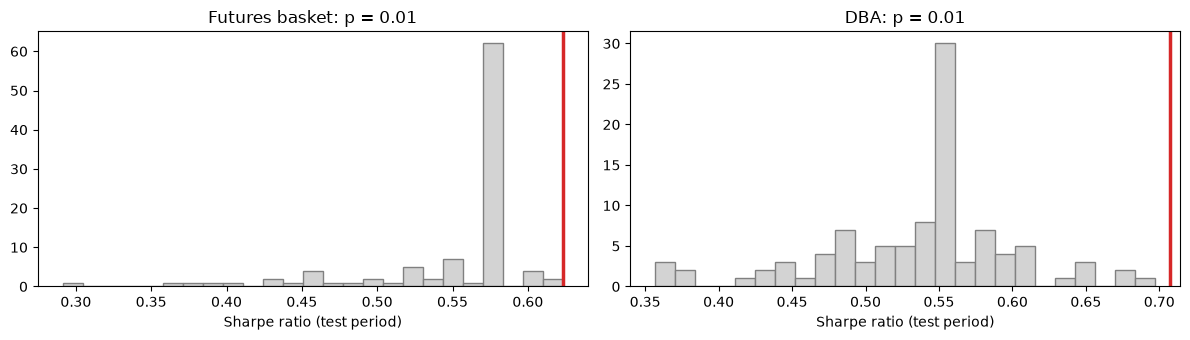

,Real SR,p-value
Futures basket,0.62,0.01
DBA,0.71,0.01


In [23]:
N_PLACEBO = 100

def run_procedure(a, cands):
    fc = {c: oos(YM[a], X, H_S, sign=True) for c, X in cands.items()}
    sel = max(fc, key=lambda c: evaluate(fc[c].loc[OOS_START:VALID_END].dropna(), H_S)[0]) if SELECTION == 'auto' else SELECTION
    e = exposure(fc[sel])
    r = (np.exp(YM[a]/100)-1).reindex(e.index)
    rf_ = rf.reindex(e.index)
    ok = r.notna() & rf_.notna() & (e.index >= TEST_START)
    return perf_m(e[ok], r[ok], rf_[ok])[1]['SR']

rng = np.random.default_rng(0)
plac = {}
fig, axes = plt.subplots(1, len(YM.columns), figsize=(12, 3.5))
n = len(df.loc[START:END])

for ax, a in zip(axes, YM.columns):
    real = run_procedure(a, CAND)
    fake = []
    for _ in range(N_PLACEBO):
        k = rng.integers(24, n-24)
        shifted = {c: pd.DataFrame(np.roll(X.loc[START:END].values, k, axis=0),
                                  index=X.loc[START:END].index, columns=X.columns)
                   for c, X in CAND.items()}
        fake.append(run_procedure(a, shifted))

    p = (1 + np.sum(np.array(fake) >= real)) / (N_PLACEBO + 1)
    plac[a] = {'Real SR': round(real, 2), 'p-value': round(p, 3)}
    ax.hist(fake, bins=25, color='lightgrey', edgecolor='grey')
    ax.axvline(real, color='tab:red', lw=2.5)
    ax.set(title=f'{a}: p = {p:.2f}', xlabel='Sharpe ratio (test period)')

plt.tight_layout()
plt.show()
display(pd.DataFrame(plac).T)

## V. Machine-learning forecasts

The strategy relies on a simple linear forecast from one climate variable. Could flexible models that use **all** the available information produce better forecasts, and so a better trading signal? The ML forecasts are compared with the linear global-warming model on the futures basket, using the same out-of-sample setup: forecasts from `OOS_START`, only data known at $t$, benchmark = historical average.
- **Features at $t$:**
  - the 4 news proxies and the real-time PC-CR;
  - the 8 economic variables (INFL, IP and KI lagged one month for publication delays);
  - past returns (last month and 12-month average);
  - abnormal Google attention per topic, if available.
- **Elastic Net:** a penalized linear model that keeps only the useful features. The penalty is chosen inside each training window by time-ordered cross-validation, with an $h$-month gap between folds so that overlapping targets do not leak.
- **Random forest:** averages many shallow decision trees, so it can capture non-linear effects and interactions, e.g. climate news mattering more when attention is high. Depth ≤ 3 and ≥ 10 months per leaf limit overfitting.
- Elastic Net, Random Forest and Gradient Boosting are refitted every 12 months.
- **Gradient Boosting:** Unlike Random Forest, which averages independently trained trees, Gradient Boosting builds trees sequentially, with each new tree correcting the errors of the previous ensemble. This allows it to capture complex nonlinear relationships, although it may increase overfitting risk.
- **CNN:** Given our limited monthly dataset (~250 observations), we favor a shallow 1D CNN over a more parameter-intensive LSTM. By applying convolutional filters to short rolling windows, the CNN can capture local temporal patterns while keeping model complexity relatively low. This approach is supported by Bai et al. (2018) and Borovykh et al. (2017), although its effectiveness with such a small sample remains uncertain.

In [24]:
from sklearn.linear_model import ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit

ML_TARGET, REFIT = YM['Futures basket'], 12
ML_NAMES = ['Elastic Net', 'Random forest', 'Gradient Boosting']

econ = E[CTRL].copy()
econ[['INFL', 'IP', 'KI']] = econ[['INFL', 'IP', 'KI']].shift(1)
feat = {**{c: df[c] for c in CRS}, 'PC_CR_rt': df.PC_CR_rt,
        **{c: econ[c] for c in CTRL}, 'r_last': ML_TARGET,
        'r_avg12': ML_TARGET.rolling(12).mean()}
if HAS_GT: feat.update({f'{c}_abn': abn(GT_all[c]) for c in GT_all.columns})
XML = pd.DataFrame(feat).loc[START:END]

def ts_cv(n, h):
    for k in (5, 4, 3, 2):
        size = (n-h)//(k+1)
        if size >= 6 and n-h-k*size >= 12:
            return TimeSeriesSplit(k, gap=h, test_size=size)
    return TimeSeriesSplit(2, gap=h)

def make_model(name, h, n):
    if name == 'Elastic Net':
        return make_pipeline(StandardScaler(),
            ElasticNetCV(l1_ratio=[.1, .5, .9], cv=ts_cv(n,h), max_iter=10000))
    if name == 'Random forest':
        return RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=10,
                                     max_features=.5, random_state=0, n_jobs=-1)
    if name == 'Gradient Boosting':
        return HistGradientBoostingRegressor(max_iter=100, learning_rate=.03,
            max_leaf_nodes=4, min_samples_leaf=15, l2_regularization=10., random_state=42)
    raise ValueError(name)

In [25]:
#Recursive out-of-sample forecasts

def oos_ml(name, h, start=OOS_START, refit=REFIT):
    d = pd.concat([fwd(ML_TARGET.loc[START:END], h).rename('y'), XML], axis=1)
    out, model, n_since = [], None, refit
    for i, t in enumerate(d.index):
        if t < pd.Timestamp(start) - pd.DateOffset(months=1) or pd.isna(d.y.iloc[i]):
            continue

        tr = d.iloc[:i-h+1].dropna()
        if tr.empty:
            continue

        pm = tr.y.mean()

        if model is None or n_since >= refit:
            model = make_model(name, h, len(tr))
            model.fit(tr[XML.columns].values, tr.y.values)
            n_since = 0

        n_since += 1
        x_t = d[XML.columns].iloc[[i]]
        f = (model.predict(x_t.values)[0]if x_t.notna().all(axis=1).iloc[0]else pm)
        out.append((t, d.y.iloc[i], f, pm))

    result = pd.DataFrame(out, columns=['t', 'y', 'f', 'pm']).set_index('t')
    return result, model, tr


ML = {
    (m, h): oos_ml(m, h)
    for m in ML_NAMES
    for h in H
}

In [26]:
#Shallow 1D CNN

#Six-month rolling windows capture local temporal patterns.
#Scaling is estimated exclusively from valid training windows.
#The network is refitted annually; fewer than 48 training
#observations trigger a historical-mean forecast.

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv1D, GlobalAveragePooling1D, Dense
from tensorflow.keras.regularizers import l2


def make_cnn(window, n_features):
    model = Sequential([Input(shape=(window, n_features)),Conv1D(4, 3, activation='relu', kernel_regularizer=l2(.01)),GlobalAveragePooling1D(),Dense(1)])
    model.compile(optimizer=tf.keras.optimizers.Adam(.001), loss='mse')
    return model


def oos_cnn(h, window=6, refit=REFIT):
    d = pd.concat([fwd(ML_TARGET.loc[START:END], h).rename('y'), XML], axis=1)
    X, y = d[XML.columns], d.y
    out, model, scaler = [], None, None
    y_mu, y_sd, n_since = 0, 1, refit

    tf.keras.utils.set_random_seed(42)

    for i, t in enumerate(d.index):
        if t < pd.Timestamp(OOS_START) - pd.DateOffset(months=1) or pd.isna(y.iloc[i]):
            continue

        train_idx = [j for j in range(window-1, i-h+1)if pd.notna(y.iloc[j])and X.iloc[j-window+1:j+1].notna().all().all()]

        if not train_idx:
            continue

        pm = y.iloc[train_idx].mean()
        current = X.iloc[i-window+1:i+1]

        if len(train_idx) < 48:
            out.append((t, y.iloc[i], pm, pm))
            continue

        if model is None or n_since >= refit:
            windows = np.stack([X.iloc[j-window+1:j+1].to_numpy() for j in train_idx])
            ytr = y.iloc[train_idx].to_numpy()
            scaler = StandardScaler().fit(windows.reshape(-1, X.shape[1]))
            Xtr = scaler.transform(windows.reshape(-1, X.shape[1])).reshape(windows.shape)
            y_mu, y_sd = ytr.mean(), max(ytr.std(), 1e-8)
            tf.keras.backend.clear_session()
            model = make_cnn(window, X.shape[1])
            model.fit(Xtr, (ytr-y_mu)/y_sd,epochs=50, batch_size=16,shuffle=False, verbose=0)
            n_since = 0

        n_since += 1

        if len(current) == window and current.notna().all().all():
            x = scaler.transform(current.to_numpy())[None, :, :]
            f = float(model(x, training=False).numpy().item()) * y_sd + y_mu
        else:
            f = pm

        out.append((t, y.iloc[i], f, pm))

    return pd.DataFrame(out, columns=['t', 'y', 'f', 'pm']).set_index('t')

CNN = {h: oos_cnn(h, window=6) for h in H}

In [27]:
# OOS comparison: common dates and benchmarks
from IPython.display import display

results = {}
for h in H:
    lin = oos(ML_TARGET, df.CR_GW, h)
    strat = oos(ML_TARGET, CAND[SEL['Futures basket']], h, sign=True)
    models = [('Linear CR_GW', lin), ('Strategy predictor', strat),
              *[(m, ML[m,h][0]) for m in ML_NAMES], ('CNN 1D', CNN[h])]

    idx = lin.dropna().index
    for _, o in models: idx = idx.intersection(o.dropna().index)

    rows = {}
    for name, o in models:
        result = o.loc[idx].copy()
        result['pm'] = lin.loc[idx, 'pm']
        r2_mean, cw = evaluate(result, h)
        r2_linear = evaluate(result.assign(pm=lin.loc[idx, 'f']), h)[0]
        rows[name] = {'R²OS % vs mean': round(r2_mean, 2),
                      'R²OS % vs linear GW': round(r2_linear, 2),
                      'CW': cw_star(cw) if name == 'Linear CR_GW' else '—'}

    results[h] = pd.DataFrame.from_dict(rows, orient='index')
    print(f'OOS forecasting — Horizon: {h} month(s)')
    display(results[h])


OOS forecasting — Horizon: 1 month(s)


,R²OS % vs mean,R²OS % vs linear GW,CW
Linear CR_GW,1.28,0.00,1.88**
Strategy predictor,-0.00,-1.30,—
Elastic Net,0.54,-0.76,—
Random forest,1.26,-0.02,—
Gradient Boosting,-2.14,-3.47,—
CNN 1D,-17.32,-18.84,—


OOS forecasting — Horizon: 6 month(s)


,R²OS % vs mean,R²OS % vs linear GW,CW
Linear CR_GW,12.74,0.00,2.73***
Strategy predictor,13.34,0.69,—
Elastic Net,-5.14,-20.49,—
Random forest,-12.66,-29.11,—
Gradient Boosting,-40.94,-61.52,—
CNN 1D,-151.47,-188.18,—


OOS forecasting — Horizon: 12 month(s)


,R²OS % vs mean,R²OS % vs linear GW,CW
Linear CR_GW,13.43,0.00,2.78***
Strategy predictor,7.29,-7.10,—
Elastic Net,-60.31,-85.19,—
Random forest,-30.88,-51.19,—
Gradient Boosting,-37.03,-58.30,—
CNN 1D,-164.39,-205.43,—


**Comment** : The linear CR_GW model shows positive out-of-sample predictive performance, particularly at 6 and 12 months, while the strategy predictor provides little additional improvement. Machine learning models generally underperform the linear benchmark, especially at longer horizons. This may reflect overfitting due to the limited monthly sample.

## VI. Comparison to other benchmark strategies 

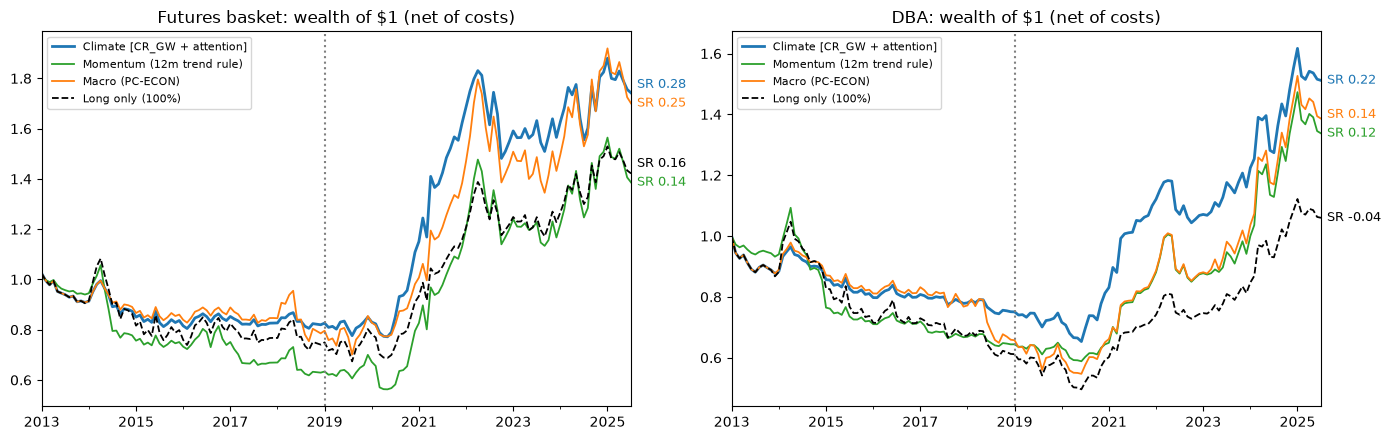

In [28]:
# Climate strategy vs simple alternatives: wealth of $1 (net of costs), common months, Sharpe ratio at the end of each line
import matplotlib.transforms as mtrans

def tilt_from_forecast(a, X, sign=True):
    'Same rule as the climate strategy: recursive H_S-month forecast -> exposure in [0.5, 1.5].'
    return exposure(oos(YM[a], X, H_S, sign=sign))

def trend_rule(a):
    'Classic time-series momentum: 150% if the past 12-month return is positive, 50% otherwise.'
    mom = YM[a].rolling(12).sum()
    e = pd.Series(np.where(mom > 0, 1.5, 0.5), mom.index).where(mom.notna()).dropna()
    e.index = e.index + pd.DateOffset(months=1); return e

fig, axes = plt.subplots(1, len(YM.columns), figsize=(14, 4.5))
for ax, a in zip(axes, YM.columns):
    EXP = {f'Climate [{SEL[a]}]': tilt_from_forecast(a, CAND[SEL[a]]),
           'Momentum (12m trend rule)': trend_rule(a),
           'Macro (PC-ECON)': tilt_from_forecast(a, E[['PC_ECON']], sign=False),
           'Long only (100%)': None}
    r = np.exp(YM[a] / 100) - 1
    idx = r.dropna().index.intersection(rf.dropna().index)
    for e in EXP.values():
        if e is not None: idx = idx.intersection(e.index)
    idx = idx[idx >= pd.Timestamp(OOS_START)]
    labels = []
    for (k, e), col in zip(EXP.items(), ['tab:blue', 'tab:green', 'tab:orange', 'k']):
        w = pd.Series(1.0, idx) if e is None else e.loc[idx]
        W, st = perf_m(w, r.loc[idx], rf.loc[idx])
        W.plot(ax=ax, color=col, lw=2 if k.startswith('Climate') else 1.3, ls='--' if e is None else '-', label=k)
        labels.append([W.iloc[-1], f"SR {st['SR']:.2f}", col])
    lo, hi = ax.get_ylim(); gap = 0.05 * (hi - lo); labels.sort()           # spread labels that would overlap
    for i in range(1, len(labels)): labels[i][0] = max(labels[i][0], labels[i - 1][0] + gap)
    tr = mtrans.blended_transform_factory(ax.transAxes, ax.transData)       # x in axes units, y in data units
    for y, txt, col in labels: ax.text(1.01, y, txt, transform=tr, color=col, fontsize=9, va='center')
    ax.axvline(pd.Timestamp(TEST_START), color='grey', ls=':'); ax.set_title(f'{a}: wealth of $1 (net of costs)'); ax.set_xlabel('')
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

**Comment** 

The climate strategy has the highest Sharpe ratio on both assets (0.28 on the futures basket and 0.22 on DBA). On the futures basket, the macro strategy comes close (0.25) and ends with a similar final wealth, while trend-following momentum does no better than holding the asset (0.14 vs 0.16). On DBA, the climate strategy is clearly ahead of macro (0.14), momentum (0.12) and buy-and-hold (−0.04). 
Its main strength is **limiting losses**: during the long commodity decline of 2014–2020, it stayed at low exposure, so its wealth remained almost flat while buy-and-hold and momentum fell, which cuts the maximum drawdown sharply (about −25% vs −38% on the futures basket, −35% vs −53% on DBA). It then raised its exposure early in the 2020–2022 rally. This protection is not systematic, however: the strategy still lost part of its gains in the 2022 correction, when its exposure was high. Climate news therefore stands comparison with standard timing signals, mainly as a tool to reduce downside risk, though its edge over macro conditions is modest on the futures basket.

## VII. Conclusion

- **Climate news predicts tradable agricultural returns.** On end-of-month futures and DBA prices, climate news predicts returns with the expected positive sign, in-sample and out of sample, mainly at horizons of 6–12 months. The effect is largely independent of economic conditions, except at short horizons on DBA, where it partly overlaps with the global demand cycle.
- **Global warming is the most robust signal.** It is the best predictor for the futures basket and the only proxy significant on both assets in every test, while natural-disaster risk fails out of sample. On DBA, the broader PC-CR index forecasts slightly better, but brings less economic value.
- **The forecasts have economic value.** A mean–variance investor gains about 1–2% per year from the forecasts, even after costs and without short selling. A simpler, low-turnover exposure tilt raises the Sharpe ratio (0.16 → 0.28 on the futures basket, −0.04 → 0.22 on DBA), cuts the maximum drawdown by about a third, and beats fake signals in a placebo test that repeats the predictor selection (p ~ 1%). It also compares well with trend-following momentum and a macro signal, mainly by limiting losses.
- **Attention and machine learning add little.** Google search attention improves six-month forecasts when combined with global-warming news. However, Elastic Net, Random Forest, Gradient Boosting and the 1D CNN all underperform the linear benchmark out of sample. This suggests that additional model complexity does not improve forecasting performance with our limited monthly dataset.
- **Limits.** The gains come from a few long-lasting positions (low exposure in 2014–2020, high exposure in 2020–2022) rather than many independent bets, and predictability is weaker after 2022. The results also depend on a revised climate-data vintage and on Google Trends data, which vary between downloads.